# Task 2.4: circuit-aware readout optimization

A stronger memory drive gives a larger buffer signal and more unwanted memory switching. We investigate that tradeoff, then temporarily enlarge the cat during readout. The comparison includes enlargement, measurement, return and relaxation.

The four challenge answers and the scope of the circuit approximation are developed in the [scientific report](../docs/task_2_4_optimization.md). This notebook inspects saved numerical evidence; it does not silently launch long simulations.

In [1]:
import json, sys, subprocess
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/config.py').is_file() and (p / 'docs/challenge_prompt_v4.md').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
show = lambda name, width=1000: display(Image(filename=str(ROOT / 'figures' / (name+'.png')), width=width))
RERUN = False
if RERUN:
    subprocess.run([sys.executable, '-m', 'tasks.task_2_4'], cwd=ROOT, check=True)
r = json.loads((ROOT / 'results/task_2_4.json').read_text())
circuit = json.loads((ROOT / 'results/task_2_4_circuit_validation.json').read_text())


## (a) Physical drive and surviving circuit terms

A microwave force coupled to the memory adds

$$H_{Z,\mathrm{lab}}=2\epsilon_Z(t)\cos(\omega_a t+\theta)(a+a^\dagger).$$

After the rotating-wave approximation,
$H_Z=\epsilon_Z(t)(e^{i\theta}a+e^{-i\theta}a^\dagger)$; the real drive uses $\theta=0$.
It is a separate microwave control. Changing the ATS pump amplitude alone does not supply this resonant memory force.

At first pump order, the cubic ATS potential gives two-photon exchange. Fifth-order phase terms make that exchange occupation dependent. There is no first-order static Kerr at the symmetric odd-potential bias. Off-resonant pump terms do produce Stark and Kerr corrections at second pump order. A consistent pump-only sixth-order phase calculation includes both cubic × cubic and linear × fifth products.

The coefficients below multiply $n_a(n_a-1)$, $n_b(n_b-1)$ and $n_an_b$, respectively; units are angular µs⁻¹. Constant and linear frequency shifts are calibrated separately.

In [2]:
display(pd.Series({k: circuit['phase6_coefficients'][k] for k in ('Ka','Kb','chi')}, name='coefficient (1/us)').to_frame())

,coefficient (1/us)
Ka,-0.017541
Kb,-9.634964
chi,-1.434297


## (b) Signal versus switching

For independently evolved initial states $|\pm\alpha\rangle_a|0\rangle_b$, define $\beta_\pm(t)=\langle b\rangle_\pm$. Contrast is the real separation of their 3–4 µs means. The reported $\Gamma_X$ is the decay rate of their memory-amplitude difference; in a two-state description it is the **sum** of the two directional switching rates.

The ideal homodyne reference is

$$\mathcal{I}(T)=\kappa_b\int_0^T[\mathrm{Re}(\beta_--\beta_+)]^2 \mathrm dt.$$

It measures conditional mean separation in shot-noise units, with $\mathrm{SNR}^2=4\mathcal{I}$. It is neither Shannon information nor a measured fidelity. Under coherent white Gaussian output and equal codeword priors, $\mathcal{I}=1$ corresponds to 15.9% classification error.

,alpha,epsilon_Z/g2,contrast,I rate (1/us),Gamma_X (1/us),Na,Nb
0,2.1,0.05,0.023790,0.009245,6.115296e-06,28.0,10.0
1,2.1,0.10,0.047575,0.036975,2.366074e-05,28.0,10.0
2,2.1,0.25,0.118852,0.230763,1.622425e-04,28.0,10.0
3,2.1,0.50,0.236890,0.916742,9.244392e-04,28.0,10.0
4,2.1,1.00,0.460372,3.462347,8.612188e-03,28.0,10.0
5,2.6,0.10,0.038441,0.024140,2.035116e-07,40.0,16.0
6,2.6,0.25,0.096096,0.150858,1.503761e-06,36.0,16.0
7,2.6,0.50,0.192144,0.603124,NaN,NaN,NaN


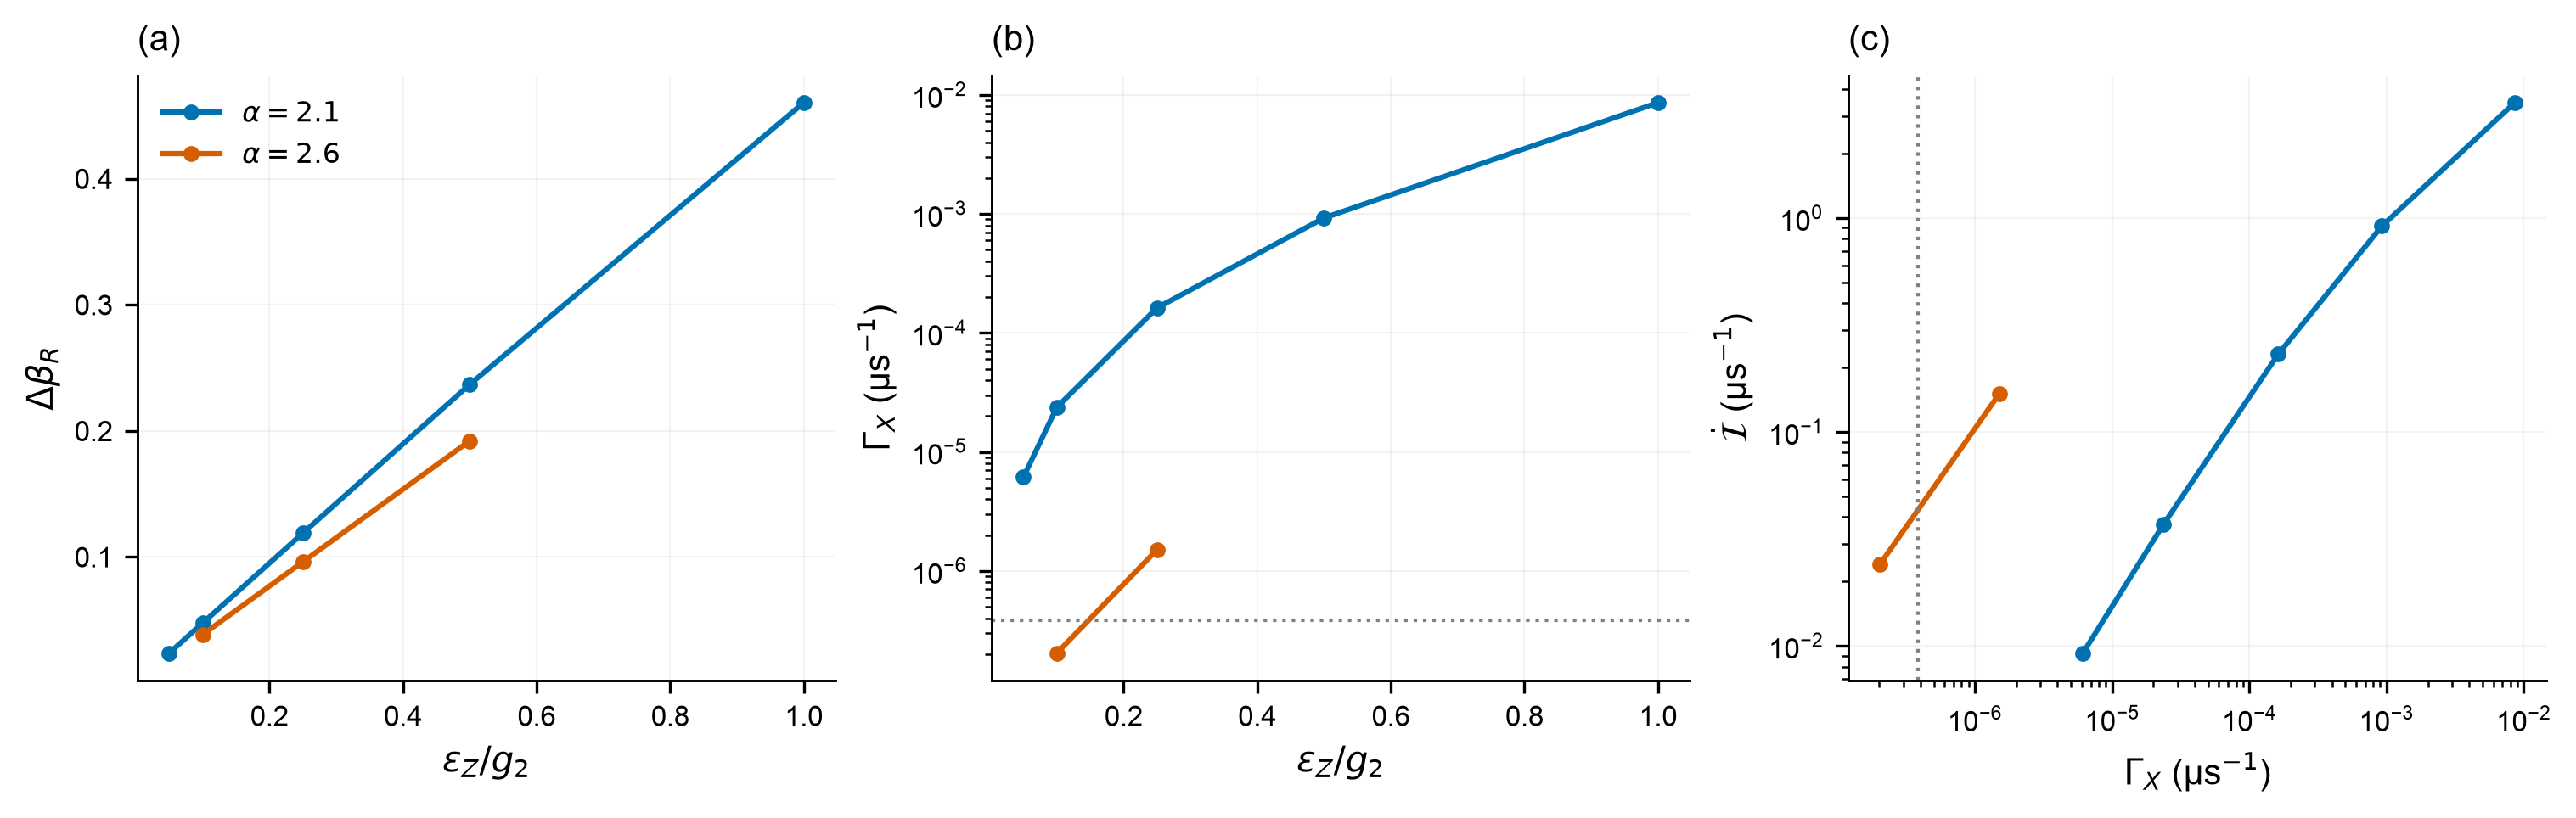

In [3]:
rows=[]
for group in r['tradeoff'].values():
    for x in group:
        rows.append({'alpha': x['alpha'], 'epsilon_Z/g2': x['ratio'],
                     'contrast': x['contrast_3_4us'],
                     'I rate (1/us)': x['mean_field_information_rate_per_us'],
                     'Gamma_X (1/us)': x.get('spectrum',{}).get('gamma_x_per_us'),
                     'Na': x.get('spectrum',{}).get('Na'), 'Nb': x.get('spectrum',{}).get('Nb')})
display(pd.DataFrame(rows))
show('task_2_4_tradeoff')

Lines connect computed points. The grey guide is undriven storage at $\alpha=2.1$. Larger drive improves contrast but increases switching at fixed cat size. The amplified-size rate points use larger rare-rate cutoffs than the initial sweep; cutoff differences and eigenpair certificates are retained in the validation archive.

## (c) Enlarge, read, restore

Increase the target from $\alpha_0=2.1$ to $\alpha_{\rm ro}=2.6$ using a quintic buffer-drive ramp, apply the memory drive, then return to storage. The conservative point uses $\epsilon_Z/g_2=0.1$ and 2-µs ramps. The optional fast point uses $0.25$ and 1-µs ramps; its switching rate is below weak readout but above undriven storage.

Both comparisons end the information budget when the memory drive turns off, then include the return and a 2-µs relaxation in total elapsed time. Wrong logical population and code leakage are evaluated after return, in the orthonormal cat-code basis at $\alpha_0$, without postselection.

The conservative static-rate point has a 0.70% last memory increment and a 0.53% separate buffer increment. The optional fast static rate retains about 4.6% memory-cutoff variation. Its finite-pulse errors receive a separate cutoff check.


,protocol,epsilon_Z/g2,ramp (us),read (us),total (us),I at drive end,worst wrong population,worst leakage
0,baseline,0.05,0.0,108.220509,110.220509,1.000000,0.000331,0.000008
1,amplified,0.10,2.0,41.399657,47.399657,0.999992,0.000008,0.000008
2,fast,0.25,1.0,6.603850,10.603850,1.000002,0.000012,0.000008


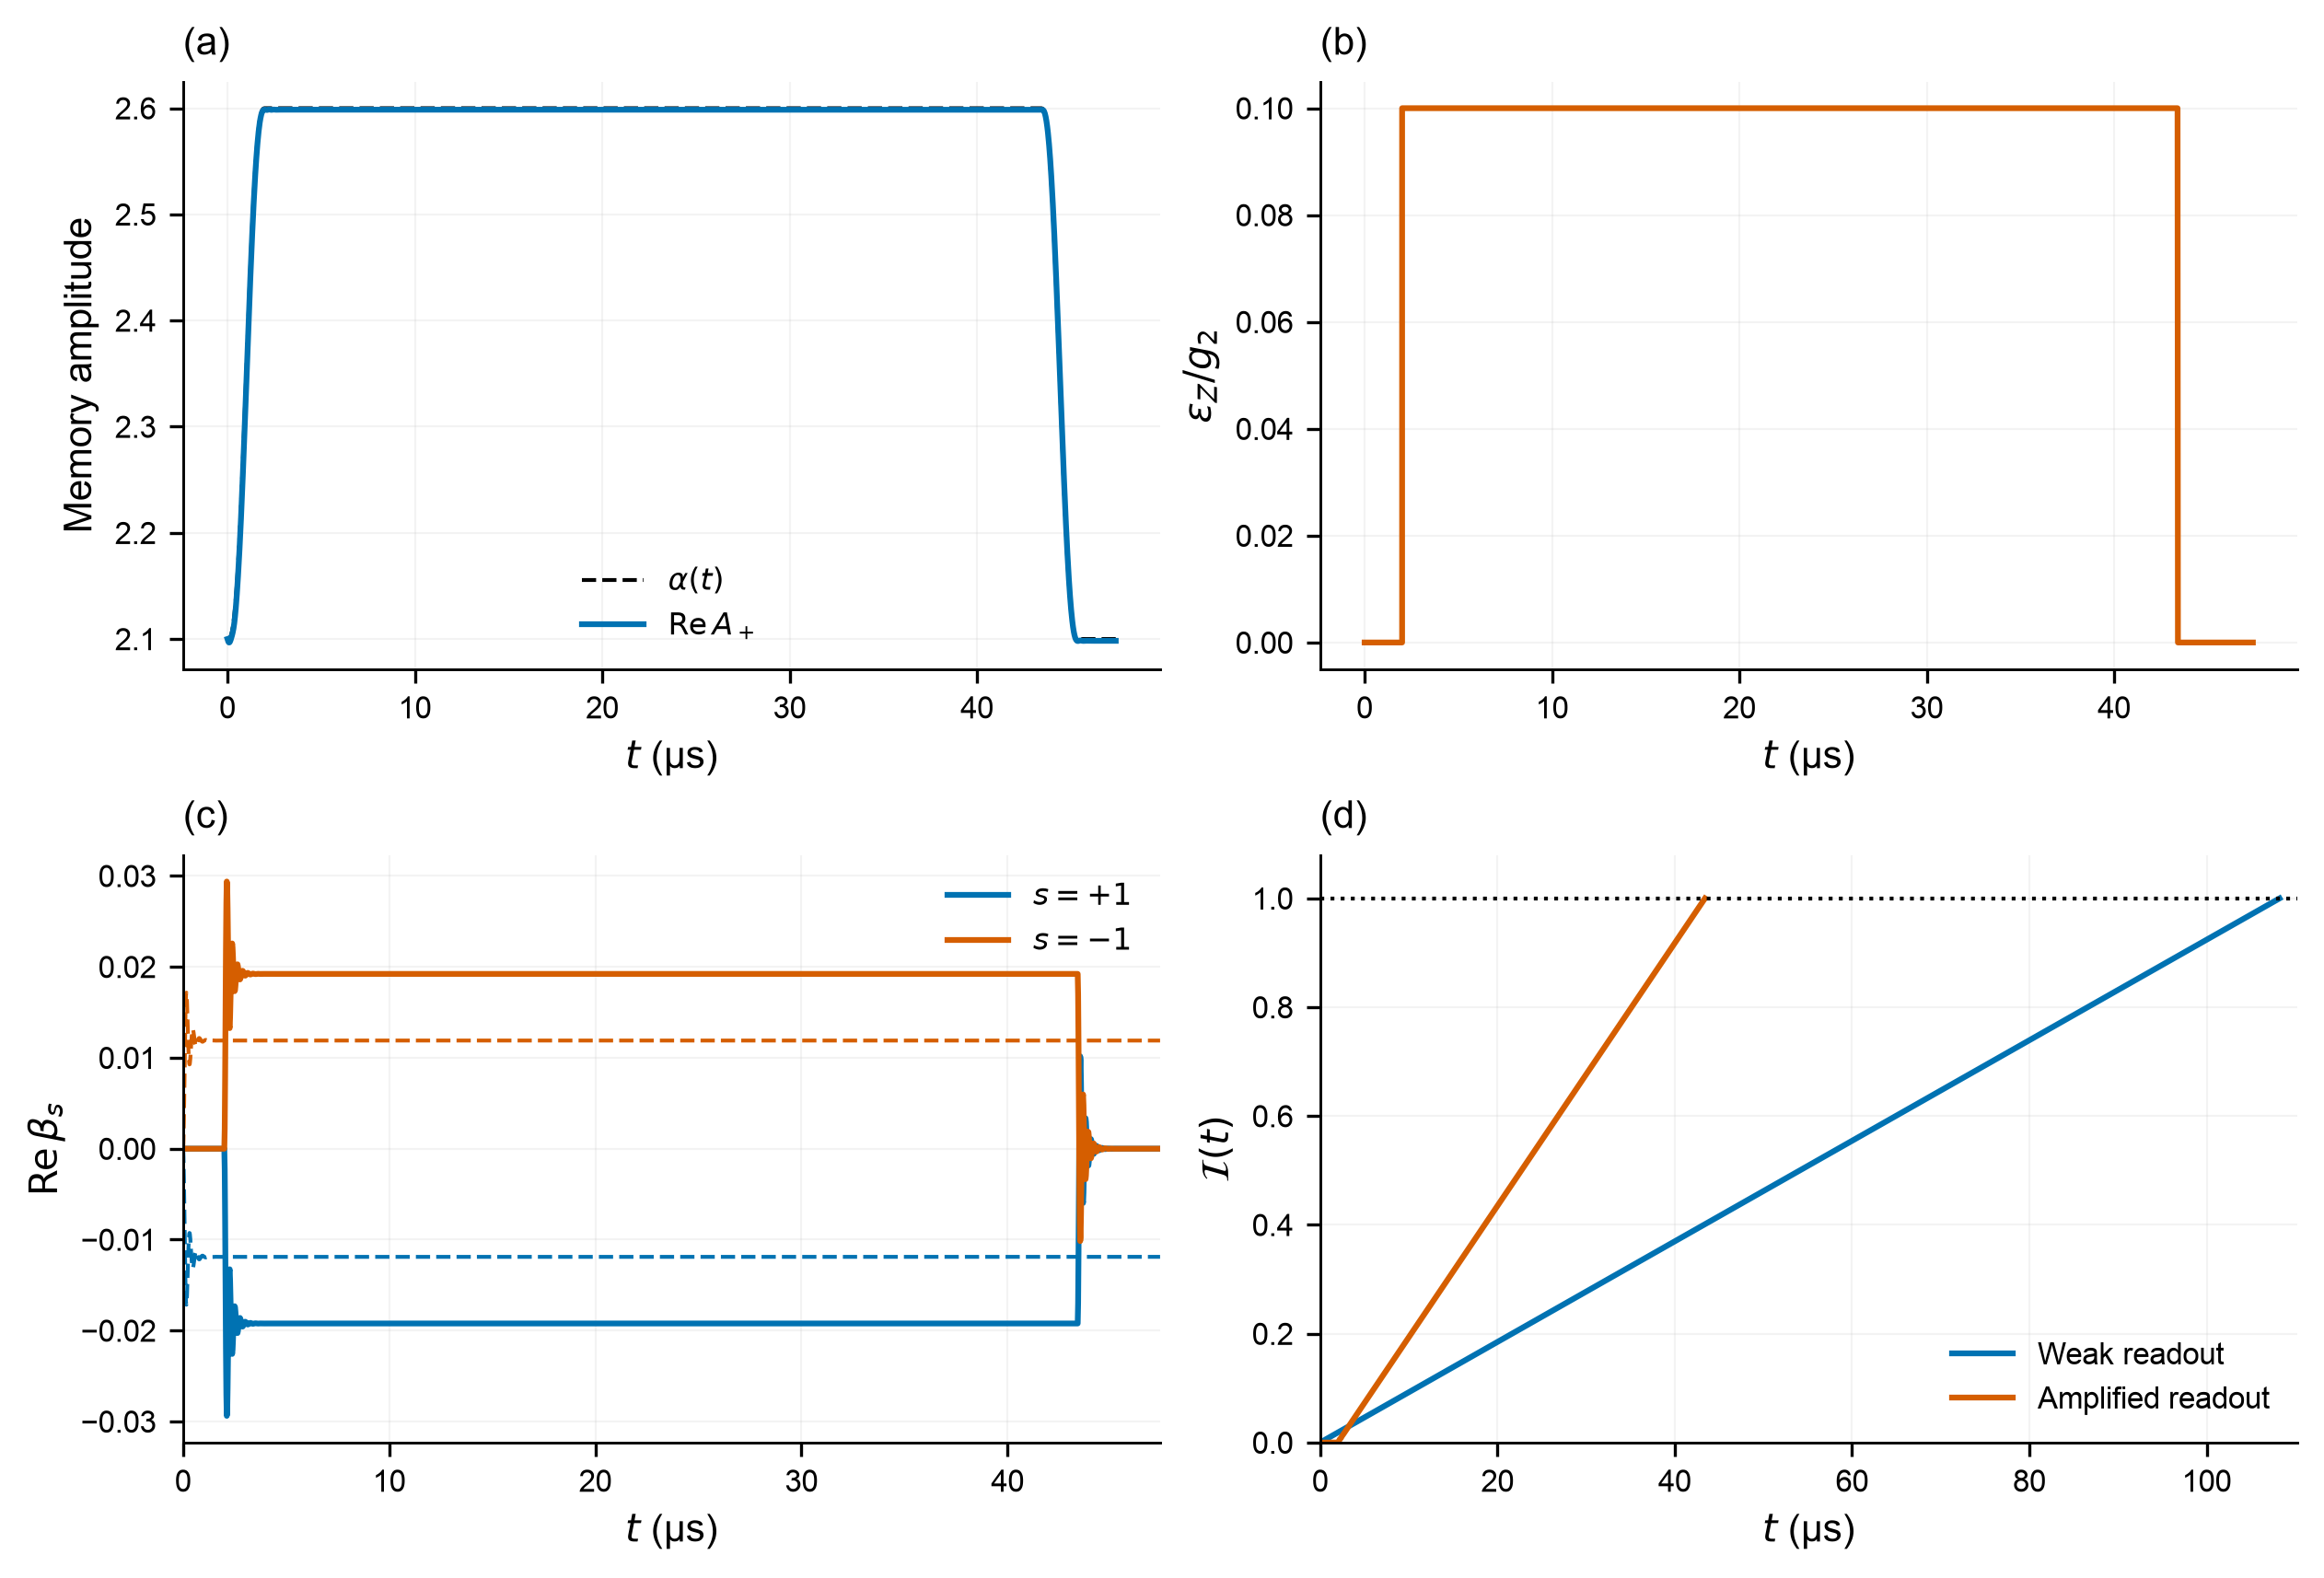

In [4]:
rows=[]
for name,x in r['cycles'].items():
    p,m=x['parameters'],x['metrics']
    rows.append({'protocol':name, 'epsilon_Z/g2':p['ratio'], 'ramp (us)':p['ramp'],
                 'read (us)':p['read_time'], 'total (us)':m['cycle_duration_us'],
                 'I at drive end':m['mean_field_information_at_read_end'],
                 'worst wrong population':max(m['wrong_logical_population']),
                 'worst leakage':max(m['final_leakage'])})
display(pd.DataFrame(rows))
show('task_2_4_protocol')

**Conservative protocol.** (a) Target $\alpha(t)$ and actual real memory
amplitude $\mathrm{Re}A_+(t)$, where $A_s(t)=\mathrm{Tr}[a\rho_s(t)]$. (b) Memory-drive envelope. (c) Buffer real fields
for initial signs $s=\pm1$; solid curves use the conservative cycle and dashed
curves the weak reference. (d) Information accumulated through each drive's end;
the dotted line is $\mathcal I_*=1$. The weak cycle uses $(32,12)$ and the
conservative cycle $(38,16)$. Time is linear in every panel. Total durations
include amplification, return and the common 2-µs final relaxation; information
after switch-off is excluded from the budget.

## (d) Why it works, and what is checked

In the weak-drive adiabatic limit, the signal information rate scales as $\epsilon_Z^2/\alpha^2$, while drive-induced switching carries an additional $e^{-2\alpha^2}$ suppression. Increasing drive alone does not improve that leading ratio; increasing cat separation does. The full two-mode calculation supplies the reported rates and trajectories because these parameters are not in the fast-buffer limit.

Numerical checks distinguish integration agreement, cutoff convergence and effective-circuit model uncertainty. Small populations at the Fock cutoff do not certify a rare rate. The full-cycle comparison also uses a directly integrated zero-drive control with the same elapsed time.

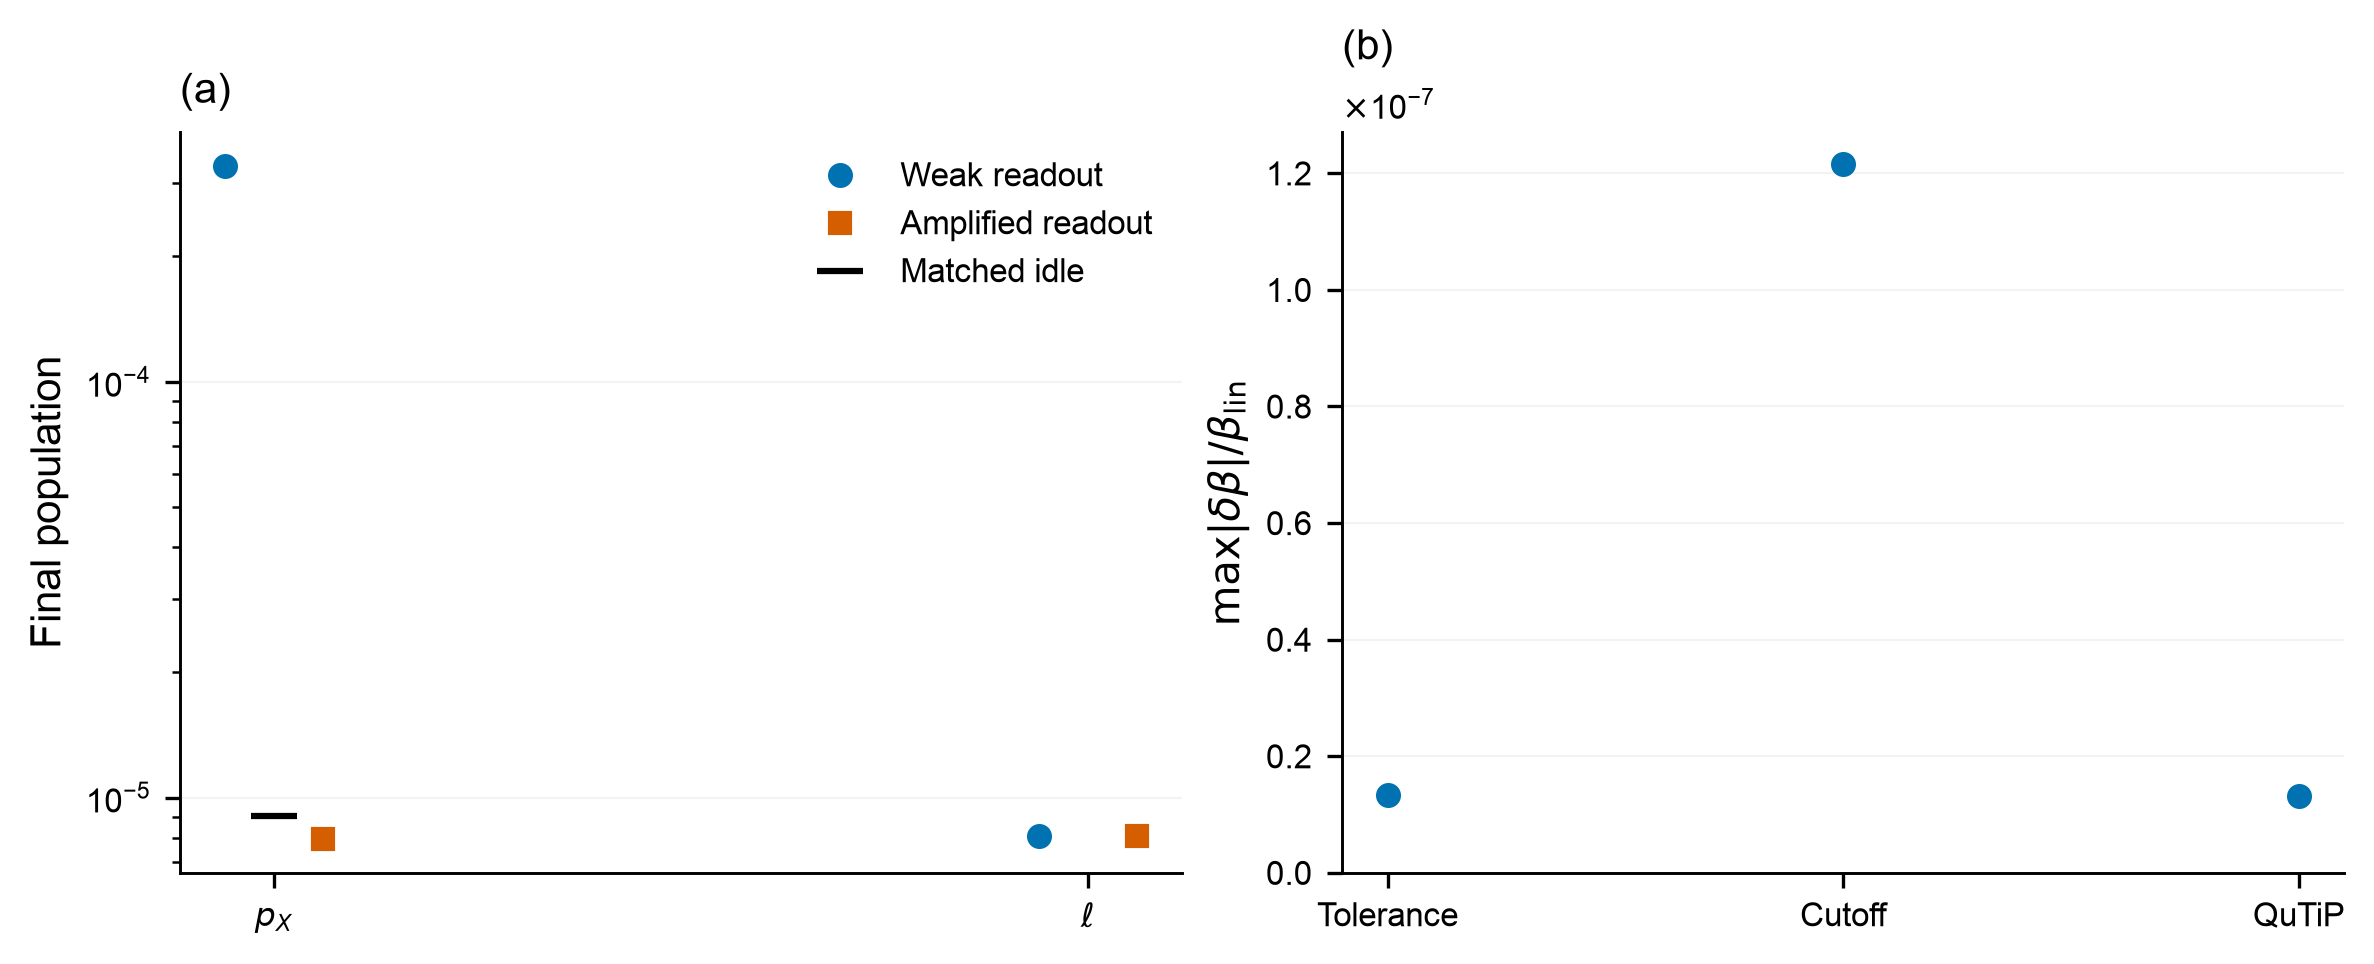

,label,max_shared_boundary_buffer_difference_fraction,wrong_population_abs_difference,leakage_abs_difference
0,Tolerance,1.333945e-08,5.061418e-14,2.650552e-16
1,Cutoff,1.216593e-07,6.158017e-08,1.528224e-12
2,QuTiP,1.314579e-08,4.183063e-13,1.589722e-13


,comparison,relative wrong-population change
0,fast_initial_memory_buffer,0.065659
1,fast_final_memory_buffer,0.005713
2,conservative_memory_buffer,0.007748


Conservative final wrong population **7.948e-06**, versus matched idle **9.059e-06**, over **47.400 µs**. Both are absolute probabilities.

In [5]:
show('task_2_4_validation')
display(pd.DataFrame(r['validation']['cycle_comparisons'])[
    ['label','max_shared_boundary_buffer_difference_fraction',
     'wrong_population_abs_difference','leakage_abs_difference']])
display(pd.DataFrame([{'comparison':k, 'relative wrong-population change':v['relative_to_larger_cutoff']}
    for k,v in r['validation']['finite_cycle_cutoff_increments'].items()]))
i=r['validation']['matched_idle_comparison']
display(Markdown(f"Conservative final wrong population **{i['conservative_wrong_population']:.4g}**, "
                 f"versus matched idle **{i['idle_wrong_population']:.4g}**, "
                 f"over **{i['duration_us']:.3f} µs**. Both are absolute probabilities."))

**Disturbance and numerical checks.** (a) Wrong logical population $p_X$ and
code leakage $\ell$ after the complete cycles. The black mark is matched-clock
idle storage. Populations are absolute and have no postselection. (b) Maximum
buffer-field differences at shared, exactly saved switch times and the final
time, normalized by the single-pointer estimate
$\beta_{\rm lin}=\epsilon_Z/(2\alpha g_2)$. “Tolerance” compares conservative
integration at $(36,14)$ with tolerances $(10^{-10},10^{-12})$ and
$(10^{-11},10^{-13})$; “Cutoff” compares $(36,14)$ with $(38,16)$;
“QuTiP” compares independent solvers for the optional fast cycle at the same
$(32,12)$ cutoff. Full-trace interpolation sensitivity is saved separately.

### Circuit sensitivity

An intentional ATS junction imbalance supplies $C\cos\Phi$. Choosing $C$ to cancel the leading cross-Kerr is a physical hardware proposal with frequency-calibration costs. The report compares the complete retained sixth-order correction and a full-phase, fundamental-pump van-Vleck sensitivity model. Numerical eigenpair accuracy does not bound omitted pump orders, bath dressing, fabrication error or flux noise.

The correction is pump-only: mixed pump/microwave counter-rotating terms at the same combined formal order are omitted. Their effect on rare switching has not been simulated, so the hardware result remains a partial-model sensitivity test.


,value
static_cosine_per_us,4426.841987
delta_EJ_per_us,-2214.111626
delta_EJ_over_EJ,-0.008810
residual_Ka_per_us,-0.003198
residual_Kb_per_us,-0.670609
residual_chi_per_us,0.000000


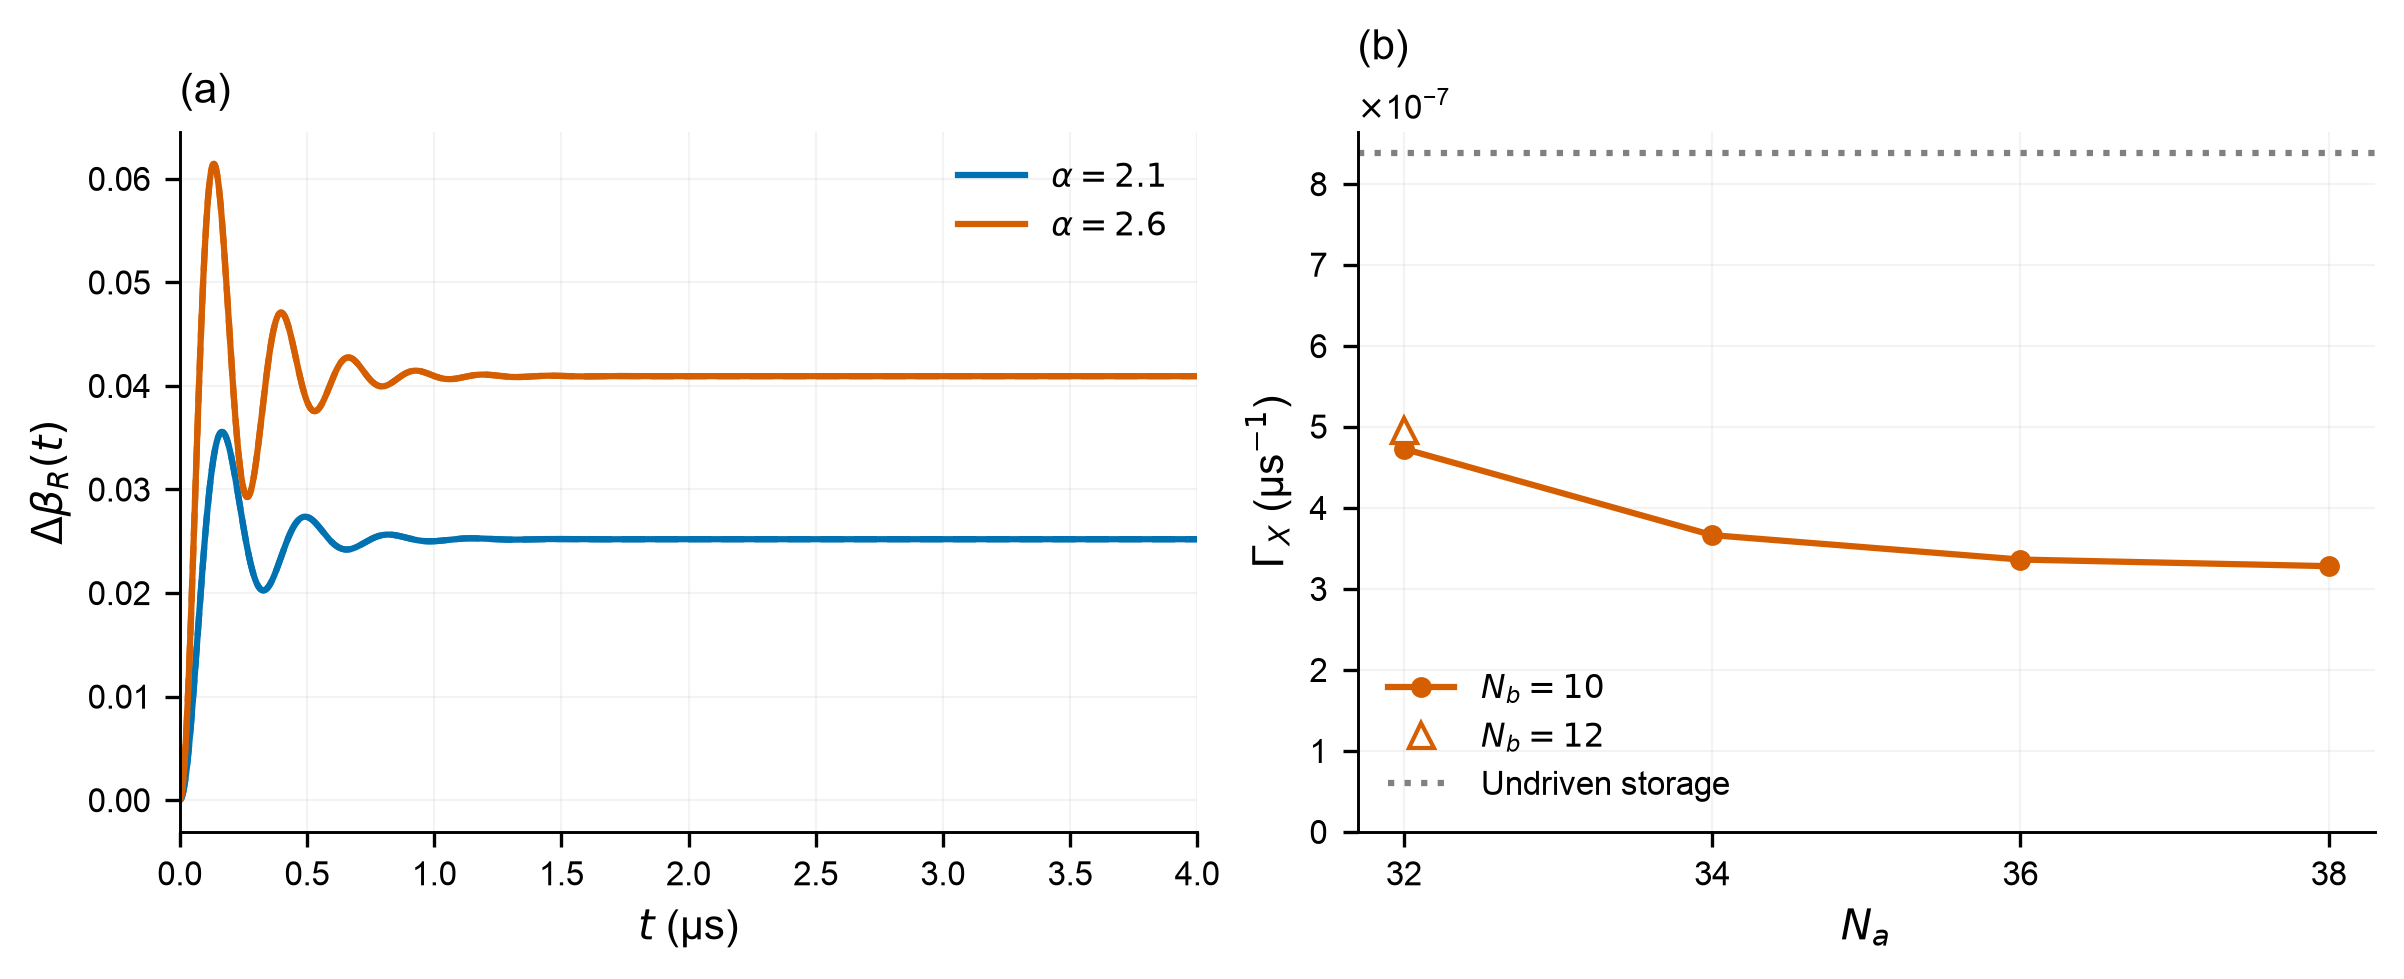

In [6]:
display(pd.Series(circuit['balanced_hardware'], name='value').to_frame())
show('task_2_4_circuit')

**Circuit sensitivity.** (a) Instantaneous real buffer-field separation in the
balanced circuit model. Blue uses $(\alpha,\epsilon_Z/g_2)=(2.1,0.05)$; orange
uses $(2.6,0.1)$. Solid curves retain the pump-only phase-six correction;
dashed curves retain the full-phase fundamental-pump correction. All field
trajectories use $(32,12)$. (b) Phase-six enlarged-readout switching rates versus
memory cutoff, with filled circles at $N_b=10$ and a hollow triangle at $N_b=12$.
The dotted guide is matched balanced undriven storage at $(32,10)$. Panel (b)
does not give full-phase switching rates.

### Less ringing is not automatically faster measurement

A two-step input shaper suppresses the dominant linearized oscillatory mode at the same peak drive. It settles sooner but accumulates slightly less information over 4 µs. This is why the protocol comparison uses integrated signal and memory disturbance rather than visual smoothness.

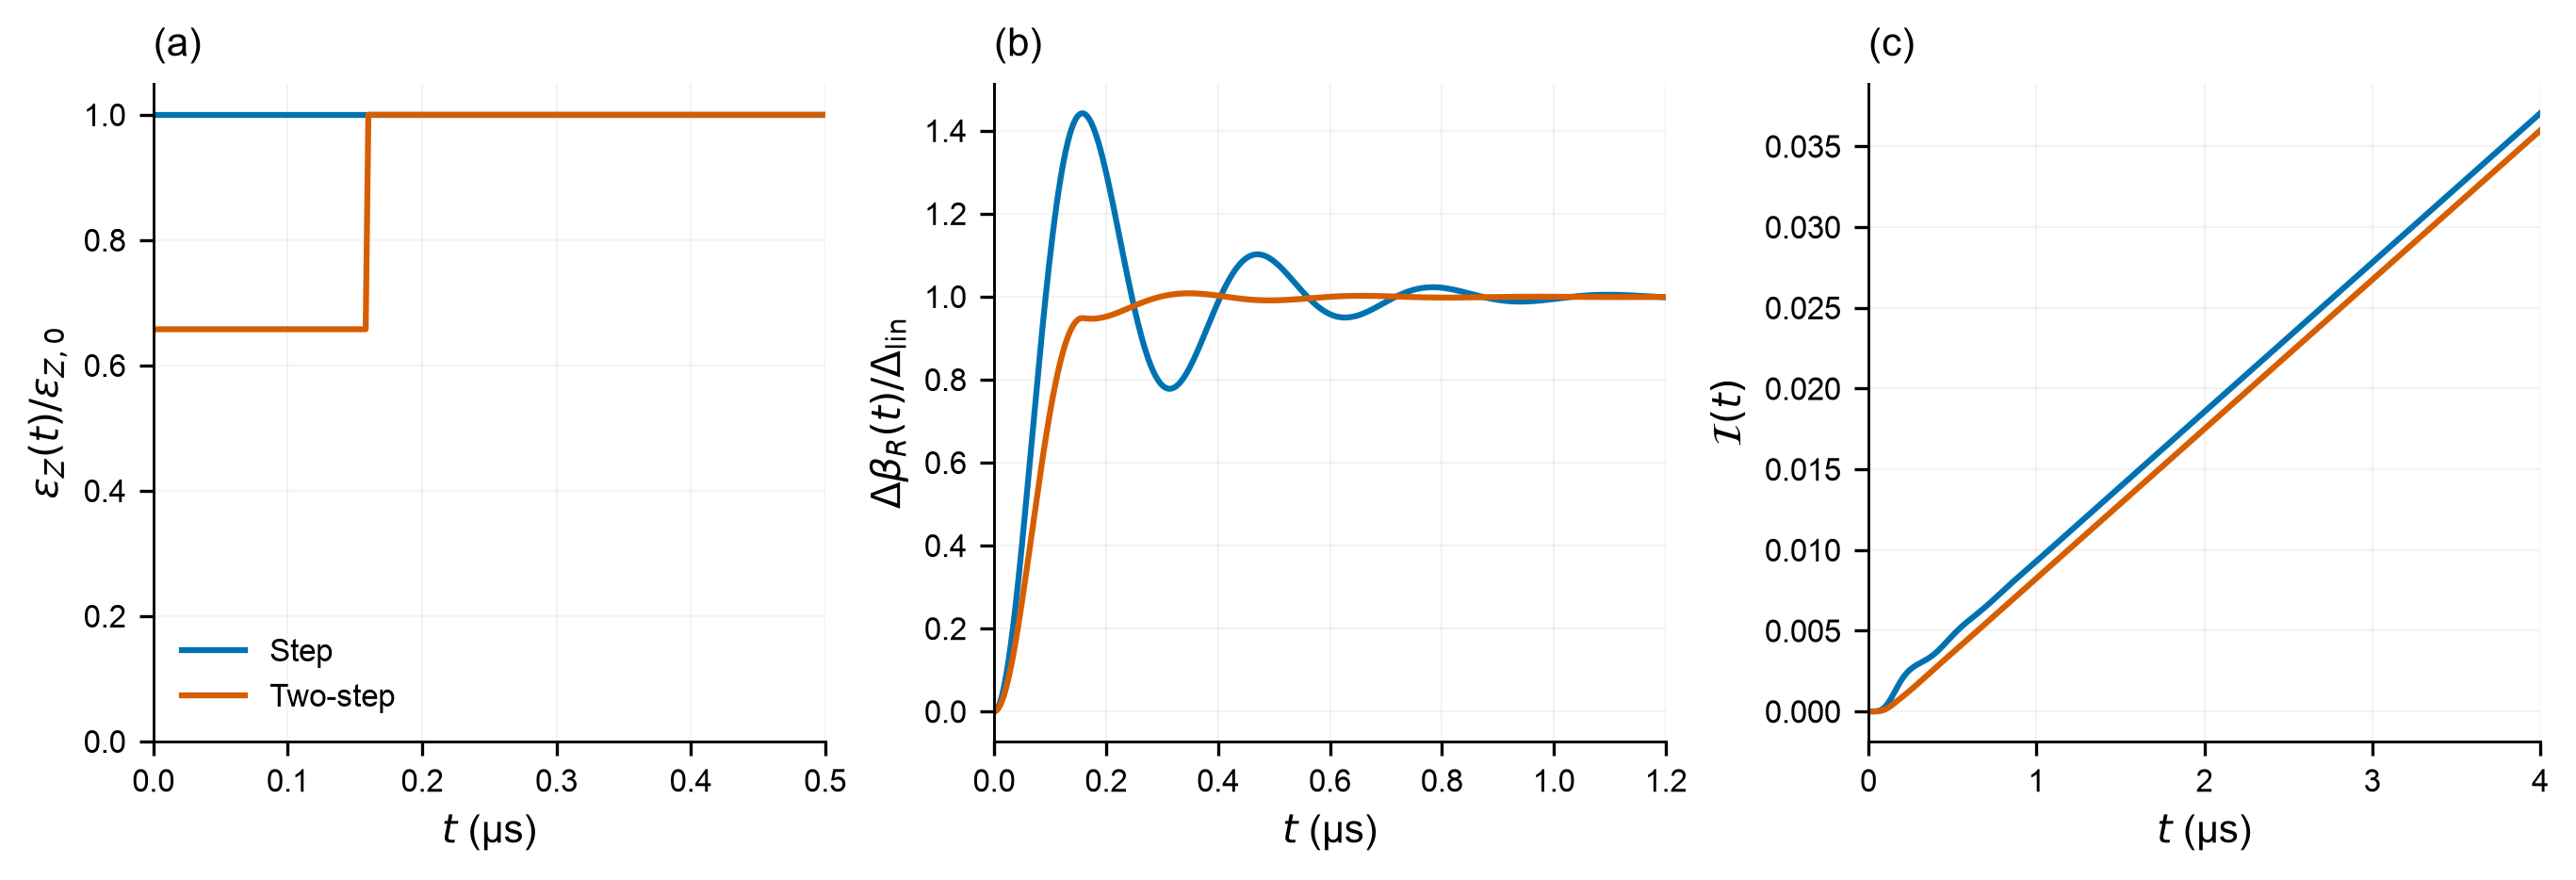

,value
delay_us,0.159313
first_fraction,0.657680
complex_settling_us,0.666000
information_4us,0.035984
step_information_4us,0.037048


In [7]:
show('task_2_4_input_shaping')
display(pd.Series({k:r['input_shaping'][k] for k in ('delay_us','first_fraction','complex_settling_us','information_4us','step_information_4us')}, name='value').to_frame())

**Input shaping.** (a) Memory drive as a fraction of its final value. (b) Real
buffer-field separation divided by $\Delta_{\rm lin}=0.05/2.1$.
(c) Integrated mean-field information. Blue denotes the abrupt step; orange
denotes the two-step pulse. Both start from the same two coherent codewords,
use the same peak drive and retain $(N_a,N_b)=(32,12)$. Settling uses the full
complex fields and the same 1% criterion as Task 2.3; the numerical curves are
unsmoothed.

### Phase-space view of the optional fast cycle

The upper/lower rows start from the positive/negative memory state. The reduced memory expands during readout and returns to its storage well. These panels and the animation use solved density matrices at $(N_a,N_b)=(32,12)$; rare logical errors require the larger-cutoff numerical checks, and cannot be assessed visually from a Wigner plot. The same color scale and origin marker are used throughout.

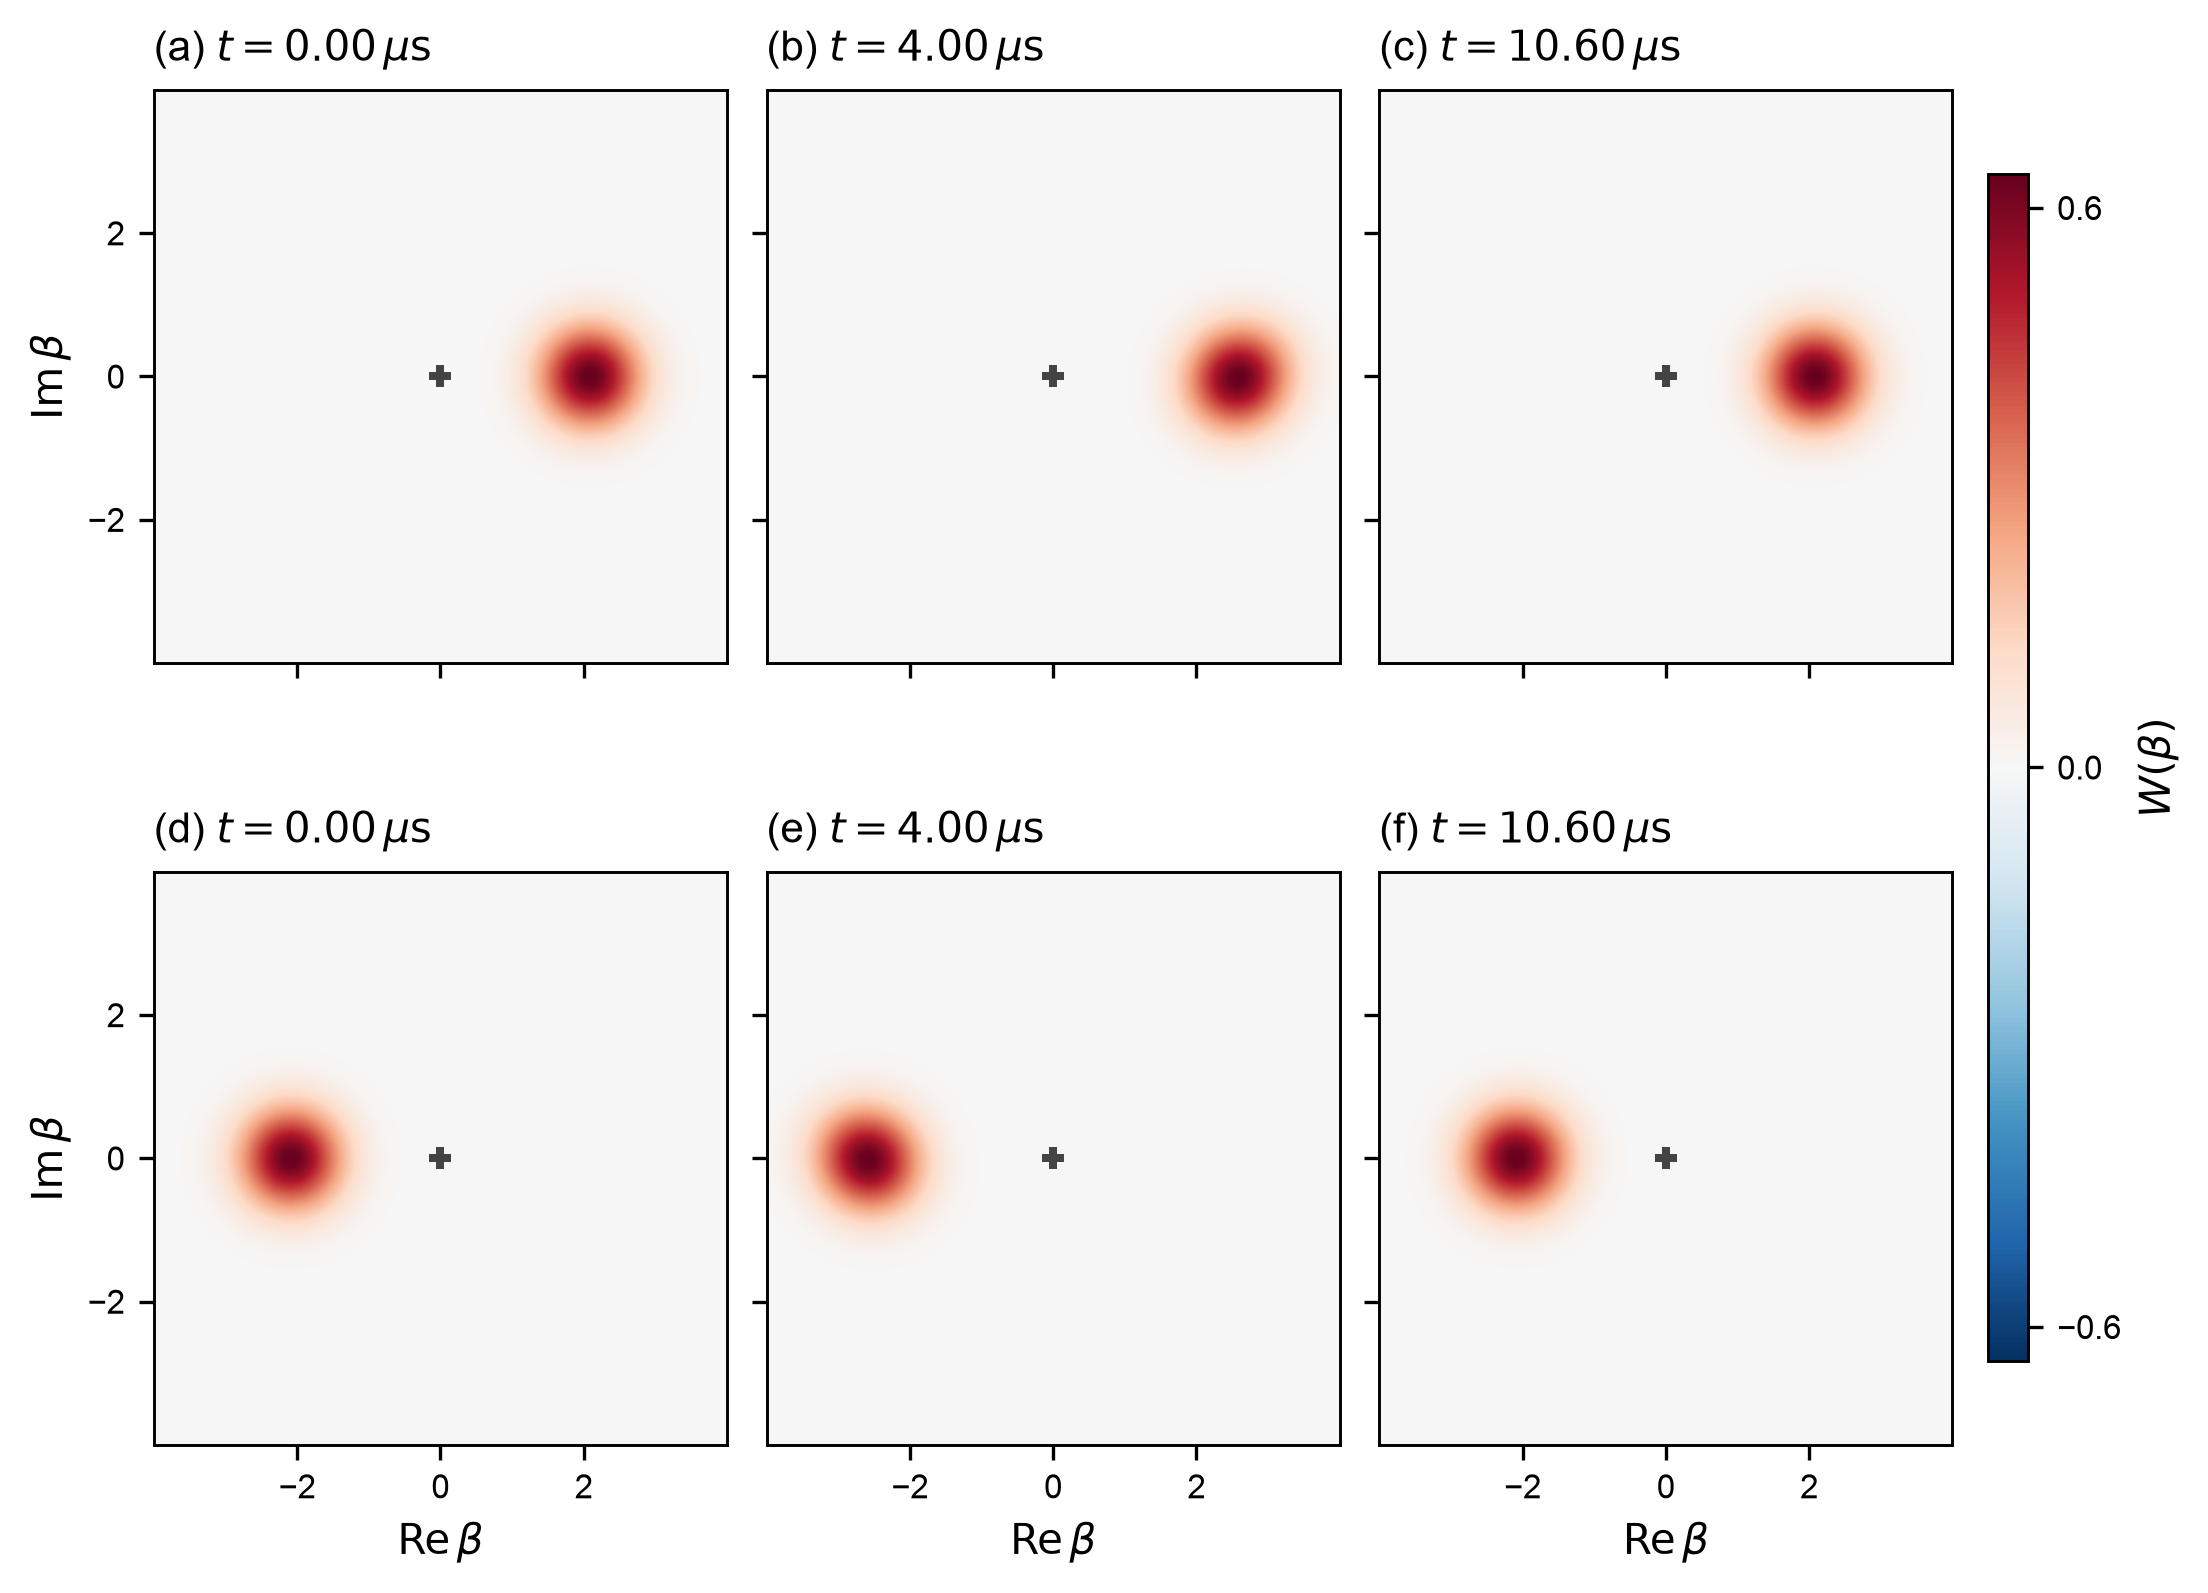

In [8]:
show('task_2_4_wigner', 850)

![Solved memory Wigner evolution of the optional fast cycle](../figures/task_2_4_wigner.gif)

## Reproduction and evidence

- `python -m tasks.task_2_4` runs the ideal study and resumes exact cached cases.
- `python -m tasks.task_2_4 --plot-only` redraws the delivered artifacts without solving.
- `python -m src.readout_rate_validation --output results/task_2_4_rate_time_checks.json` independently checks resolvable switching rates with full-complex QuTiP evolution.
- `python -m unittest discover -s tests -v` runs physical representation, circuit, solver and measurement checks.

See the [report](../docs/task_2_4_optimization.md) for precise circuit-model assumptions, cutoff limitations and source references. Saved JSON records and NPZ trajectories are in [results](../results/). Codex assisted with derivation, implementation, numerical experiment design and reporting.